# Lab 2 – TV6: Sobel, Prewitt và Bilateral Filter

**Mục tiêu:** tính $G_x$, $G_y$, độ lớn gradient; tự khai báo kernel Prewitt để so sánh Sobel; khảo sát cạnh trước/sau Bilateral và minh họa mất cạnh nhỏ khi lọc quá mạnh.

Dùng ảnh thật `04_camera.png`, `19_text.png` của nhóm. Nhiễu được sinh với seed cố định; hình tổng hợp ở cuối chỉ dùng kiểm chứng một cạnh yếu đã biết. Kết quả được lưu tại `lab_2/result/figures/tv6_edge_bilateral/`.

## 1. Cơ sở và quy ước

Với trục $x$ sang phải, $y$ xuống dưới, dùng các kernel 3×3 sau (OpenCV áp dụng tương quan):

```text
Sobel Kx          Sobel Ky         Prewitt Kx       Prewitt Ky
[-1  0  1]       [-1 -2 -1]       [-1  0  1]       [-1 -1 -1]
[-2  0  2]       [ 0  0  0]       [-1  0  1]       [ 0  0  0]
[-1  0  1]       [ 1  2  1]       [-1  0  1]       [ 1  1  1]
```

$M=\sqrt{G_x^2+G_y^2}$. Tính bằng `float32` để giữ cả đạo hàm âm; chuyển trực tiếp sang `uint8` sẽ làm mất thông tin. Viền dùng `BORDER_REFLECT_101`. Sobel làm trơn theo trọng số 1–2–1 ở phương vuông góc đạo hàm; Prewitt dùng 1–1–1.

Các hàm trả **gradient thô**. Để so sánh độ lớn công bằng, chia Sobel cho 4 và Prewitt cho 3 (hệ số đáp ứng của một cạnh bậc thang thẳng). Đây không phải chuẩn hóa min–max từng ảnh. Cả hai dùng chung giới hạn màu; các toán tử vẫn khác nhau ở chi tiết và hướng cạnh.

Bilateral lấy trung bình có trọng số theo **khoảng cách không gian** và **chênh lệch cường độ**:
$w(p,q)=\exp[-\|p-q\|^2/(2\sigma_s^2)]\exp[-(I_p-I_q)^2/(2\sigma_c^2)]$.
`d` là đường kính lân cận; `sigma_space` theo pixel, `sigma_color` theo mức xám. Khi `sigma_color` lớn, điểm ở hai phía cạnh dễ được trộn; tăng vùng lân cận cũng có thể xóa chi tiết nhỏ.

In [1]:
from pathlib import Path
import sys, csv
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Chạy được từ gốc repository hoặc thư mục notebook.
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'lab_2/src/common.py').is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from lab_2.src.common import read_image, bgr_to_rgb
from lab_2.src.edge_detection import sobel_edges, prewitt_edges
from lab_2.src.nonlinear_filters import apply_bilateral_filter

DATA = ROOT / 'lab_2/data/input'
OUT = ROOT / 'lab_2/result/figures/tv6_edge_bilateral'
OUT.mkdir(parents=True, exist_ok=True)
SEED, EDGE_THRESHOLD = 2026, 20.0
plt.rcParams.update({'font.size': 10, 'figure.dpi': 100})
camera = read_image(DATA / '04_camera.png', as_gray=True)
text = read_image(DATA / '19_text.png', as_gray=True)

def finish(fig, name):
    fig.savefig(OUT / name, dpi=140, bbox_inches='tight')
    plt.show()
    plt.close(fig)

def gray(ax, image, title):
    ax.imshow(image, cmap='gray', vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis('off')

print('Ảnh:', camera.shape, text.shape, '| dtype:', camera.dtype)
print('Seed:', SEED, '| Ngưỡng cạnh chung:', EDGE_THRESHOLD)

Ảnh: (512, 512) (172, 448) | dtype: uint8
Seed: 2026 | Ngưỡng cạnh chung: 20.0


## 2. Kiểm tra giao diện và đầu vào

Kiểm tra ảnh xám, ảnh BGR, ảnh hằng, kiểu đầu ra và ví dụ lỗi. Kiểm thử đầy đủ các kernel/tham số nằm trong bộ kiểm thử của module.

In [2]:
for detector in (sobel_edges, prewitt_edges):
    parts = detector(camera)
    assert len(parts) == 3
    assert all(x.shape == camera.shape and x.dtype == np.float32 for x in parts)
    assert all(np.isfinite(x).all() for x in parts)
    np.testing.assert_allclose(parts[2], np.hypot(parts[0], parts[1]))
    assert all(np.count_nonzero(x) == 0 for x in detector(np.full((16, 16), 90, np.uint8)))
bgr = cv2.cvtColor(camera, cv2.COLOR_GRAY2BGR)
assert bgr_to_rgb(bgr).shape == bgr.shape
np.testing.assert_array_equal(sobel_edges(bgr)[2], sobel_edges(camera)[2])
assert apply_bilateral_filter(bgr).shape == bgr.shape
assert apply_bilateral_filter(camera).dtype == np.uint8
bad_cases = [
    ('Sobel: float32 thay vì uint8', lambda: sobel_edges(camera.astype(np.float32))),
    ('Prewitt: ảnh rỗng', lambda: prewitt_edges(np.empty((0, 0), np.uint8))),
    ('Bilateral: sigma âm', lambda: apply_bilateral_filter(camera, sigma_color=-1)),
    ('Bilateral: ảnh 4 kênh', lambda: apply_bilateral_filter(np.zeros((8, 8, 4), np.uint8))),
]
for label, action in bad_cases:
    try:
        action()
    except (TypeError, ValueError) as exc:
        print(label, '->', type(exc).__name__, str(exc))
    else:
        raise AssertionError('Đầu vào sai chưa bị từ chối: ' + label)
print('PASS: kiểm tra hợp lệ và không hợp lệ.')

Sobel: float32 thay vì uint8 -> TypeError Ảnh phải có kiểu dữ liệu uint8, nhận được: float32
Prewitt: ảnh rỗng -> ValueError Ảnh đầu vào không được rỗng.
Bilateral: sigma âm -> ValueError sigma_color must be positive
Bilateral: ảnh 4 kênh -> ValueError Color image must have 3 channels
PASS: kiểm tra hợp lệ và không hợp lệ.


## 3. Sobel theo hai hướng

$G_x$ nhạy với thay đổi trái–phải (thường thấy cạnh đứng), $G_y$ nhạy với thay đổi trên–dưới (cạnh ngang). Hai hình đạo hàm dùng cùng thang màu đối xứng quanh 0; độ lớn dùng giá trị không âm. Hình này giữ nguyên hệ số Sobel thô.

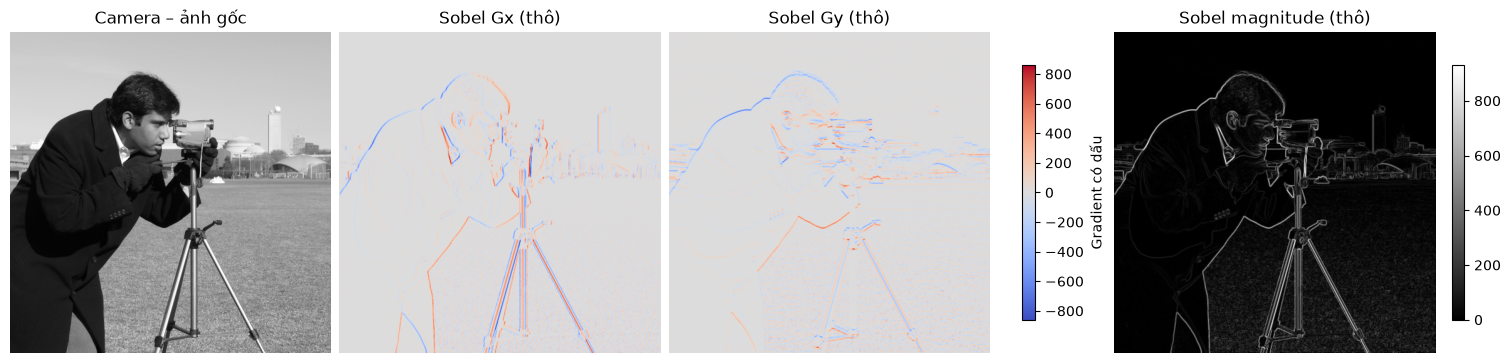

Gx: [-860, 851], Gy: [-722, 784]


In [3]:
gx, gy, magnitude = sobel_edges(camera)
signed_limit = max(float(np.abs(gx).max()), float(np.abs(gy).max()))
fig, axes = plt.subplots(1, 4, figsize=(15, 4), constrained_layout=True)
gray(axes[0], camera, 'Camera – ảnh gốc')
for ax, values, title in zip(axes[1:3], (gx, gy), ('Sobel Gx (thô)', 'Sobel Gy (thô)')):
    im = ax.imshow(values, cmap='coolwarm', vmin=-signed_limit, vmax=signed_limit)
    ax.set_title(title); ax.axis('off')
fig.colorbar(im, ax=list(axes[1:3]), shrink=0.65, label='Gradient có dấu')
im = axes[3].imshow(magnitude, cmap='gray', vmin=0, vmax=float(magnitude.max()))
axes[3].set_title('Sobel magnitude (thô)'); axes[3].axis('off')
fig.colorbar(im, ax=axes[3], shrink=0.65)
finish(fig, '01_sobel_components.png')
print(f'Gx: [{gx.min():.0f}, {gx.max():.0f}], Gy: [{gy.min():.0f}, {gy.max():.0f}]')

## 4. So sánh Sobel và Prewitt trên cùng ảnh

Hiển thị hai ảnh thật để tránh kết luận từ một vùng duy nhất. Mọi ảnh độ lớn bên dưới dùng **cùng một thang màu**, sau khi hiệu chỉnh hệ số 4/3 đã nêu. Không dùng ảnh nhị phân để thay thế độ lớn gradient.

Camera: trung bình |Sobel/4 − Prewitt/3| = 1.055
Text: trung bình |Sobel/4 − Prewitt/3| = 0.832


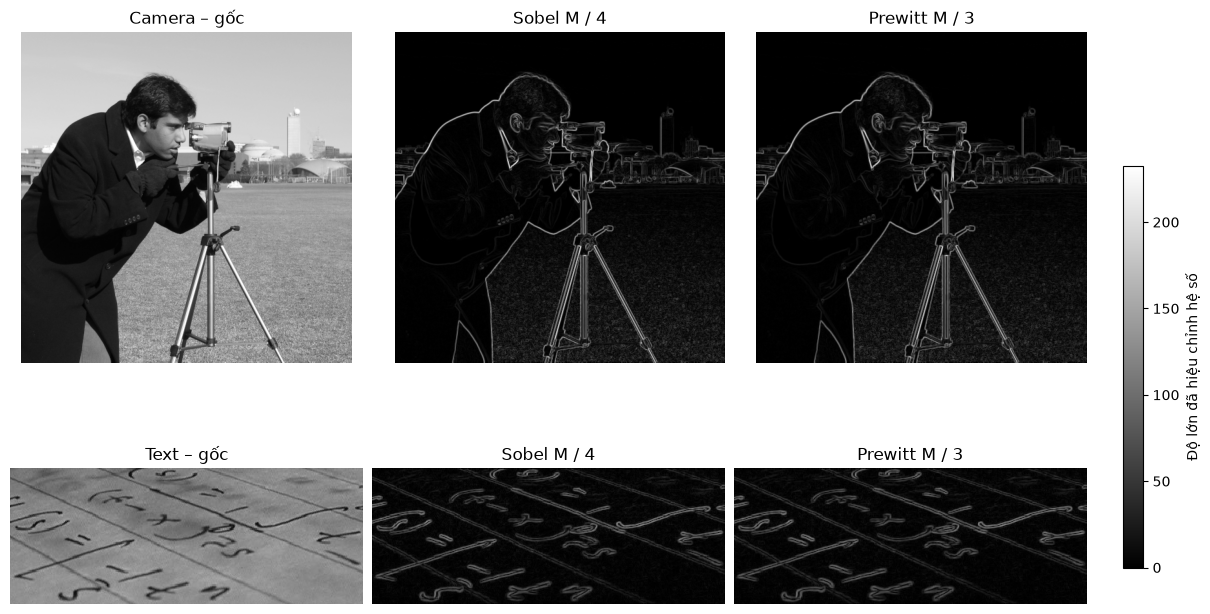

In [4]:
comparisons = [(name, image, sobel_edges(image)[2] / 4, prewitt_edges(image)[2] / 3)
               for name, image in [('Camera', camera), ('Text', text)]]
common_max = max(float(m.max()) for _, _, s, p in comparisons for m in (s, p))
fig, axes = plt.subplots(2, 3, figsize=(12, 7), constrained_layout=True)
for row, (name, original, sobel_m, prewitt_m) in zip(axes, comparisons):
    gray(row[0], original, name + ' – gốc')
    for ax, values, title in zip(row[1:], (sobel_m, prewitt_m), ('Sobel M / 4', 'Prewitt M / 3')):
        im = ax.imshow(values, cmap='gray', vmin=0, vmax=common_max)
        ax.set_title(title); ax.axis('off')
    print(f'{name}: trung bình |Sobel/4 − Prewitt/3| = {np.mean(np.abs(sobel_m-prewitt_m)):.3f}')
fig.colorbar(im, ax=axes[:, 1:].ravel().tolist(), shrink=0.6, label='Độ lớn đã hiệu chỉnh hệ số')
finish(fig, '02_sobel_prewitt.png')

**Nhận xét:** hai toán tử cùng làm nổi đường bao và chữ. Khác biệt ở vùng chi tiết phản ánh cách lấy trung bình theo phương vuông góc: Sobel nhấn hàng/cột giữa, Prewitt cho trọng số đều. Độ lớn gần nhau không có nghĩa hai kernel giống nhau; không có nhãn cạnh chuẩn để tuyên bố toán tử nào chính xác hơn.

## 5. Cạnh trước và sau lọc trên ảnh có nhiễu

Thêm nhiễu Gaussian $\sigma=12$ vào camera, **clip trong miền float trước khi ép uint8**. Mọi bộ lọc nhận đúng cùng ảnh nhiễu. Gaussian 5×5, $\sigma=1$ là mốc so sánh; Bilateral vừa `(9, 35, 5)` và mạnh `(15, 150, 15)` lần lượt là `(d, sigma_color, sigma_space)`.

Hàng 2 dùng cùng Sobel `/4` và thang màu; hàng 3 dùng cùng ngưỡng 20. Đây là bản đồ ngưỡng gradient đơn giản, chưa phải phép đánh giá phát hiện cạnh có ground truth.

Gốc sạch: MSE so với ảnh trước khi thêm nhiễu = 0.00
Có nhiễu: MSE so với ảnh trước khi thêm nhiễu = 139.07
Gaussian 5×5, σ=1: MSE so với ảnh trước khi thêm nhiễu = 82.05
Bilateral vừa (9,35,5): MSE so với ảnh trước khi thêm nhiễu = 53.70
Bilateral mạnh (15,150,15): MSE so với ảnh trước khi thêm nhiễu = 243.62


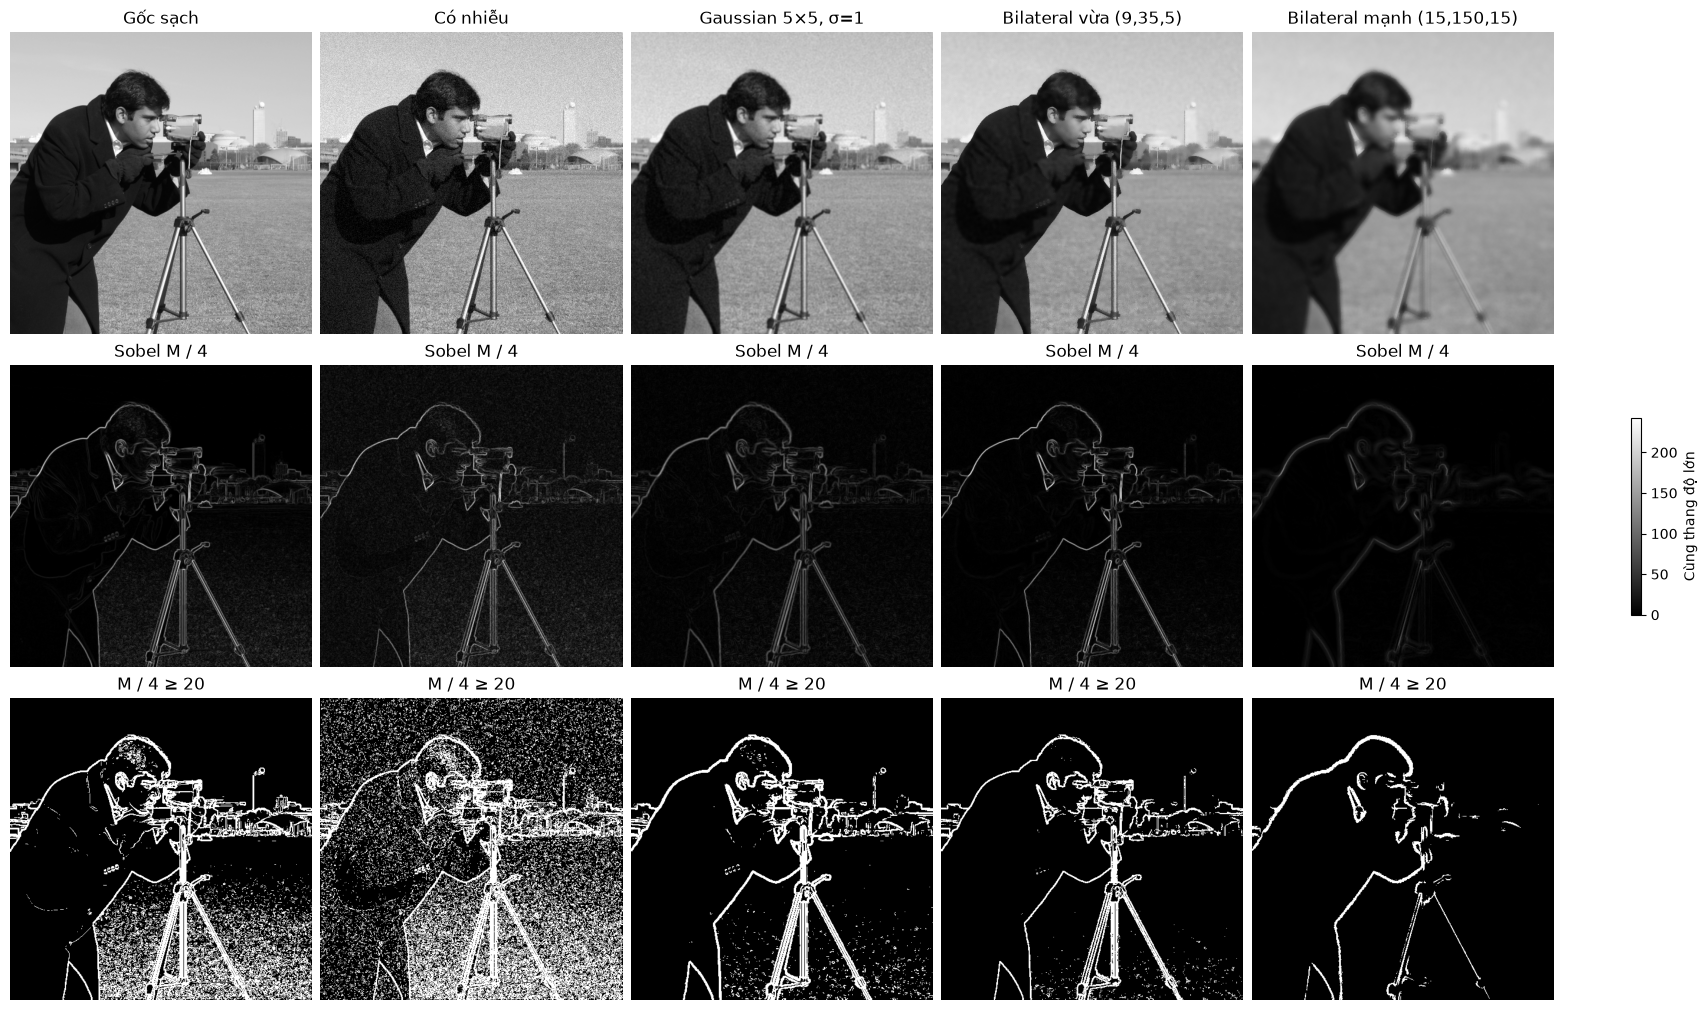

In [5]:
rng = np.random.default_rng(SEED)
noisy = np.clip(camera.astype(np.float32) + rng.normal(0, 12, camera.shape), 0, 255).astype(np.uint8)
variants = {
    'Gốc sạch': camera,
    'Có nhiễu': noisy,
    'Gaussian 5×5, σ=1': cv2.GaussianBlur(noisy, (5, 5), 1, borderType=cv2.BORDER_REFLECT_101),
    'Bilateral vừa (9,35,5)': apply_bilateral_filter(noisy, 9, 35, 5),
    'Bilateral mạnh (15,150,15)': apply_bilateral_filter(noisy, 15, 150, 15),
}
edge_maps = {name: sobel_edges(image)[2] / 4 for name, image in variants.items()}
edge_max = max(float(values.max()) for values in edge_maps.values())
fig, axes = plt.subplots(3, 5, figsize=(17, 10), constrained_layout=True)
for j, (name, image) in enumerate(variants.items()):
    gray(axes[0, j], image, name)
    im = axes[1, j].imshow(edge_maps[name], cmap='gray', vmin=0, vmax=edge_max)
    axes[1, j].set_title('Sobel M / 4'); axes[1, j].axis('off')
    axes[2, j].imshow(edge_maps[name] >= EDGE_THRESHOLD, cmap='gray', vmin=0, vmax=1)
    axes[2, j].set_title('M / 4 ≥ 20'); axes[2, j].axis('off')
    mse = np.mean((image.astype(np.float32) - camera.astype(np.float32)) ** 2)
    print(f'{name}: MSE so với ảnh trước khi thêm nhiễu = {mse:.2f}')
fig.colorbar(im, ax=axes[1, :].tolist(), shrink=0.65, label='Cùng thang độ lớn')
finish(fig, '03_filter_edge_comparison.png')

**Kết quả với seed 2026:** MSE của ảnh nhiễu là **139.07**, Gaussian **82.05**, Bilateral vừa **53.70**, Bilateral mạnh **243.62**. Cấu hình vừa phục hồi ảnh này tốt hơn theo MSE; cấu hình mạnh đã làm mất chi tiết đến mức MSE cao hơn cả ảnh nhiễu.

**Cách đọc kết quả:** nhiễu sinh nhiều đáp ứng nhỏ trong vùng đồng nhất. Lọc giảm các đáp ứng này; Bilateral vừa còn ưu tiên điểm có cường độ gần nhau quanh đường bao. Gaussian có thể làm mềm cả đường bao. Bilateral mạnh làm phẳng nhiều chi tiết hơn; không nên tăng tham số chỉ để bản đồ cạnh trông ít điểm trắng. MSE chỉ đo phục hồi ảnh đã biết trước khi thêm nhiễu, không đo độ đúng của cạnh và không chứng minh bộ lọc luôn tốt hơn trên ảnh khác.

## 6. Minh họa có kiểm soát: cạnh nhỏ bị mất khi lọc mạnh

Ảnh **tổng hợp**, nền 70, vạch sáng rộng 3 pixel ở cột `[60:63)` có mức 94 (tương phản 24), cạnh lớn ở cột 160 chuyển lên 200. Thêm nhiễu Gaussian $\sigma=6$ với seed 2026. Dùng Bilateral vừa `(9,12,5)` ở đây vì vạch chỉ chênh 24 mức; bộ lọc mạnh vẫn `(15,150,15)`.

Đo profile trung bình trên hàng `[16:112)`. Tương phản vạch = trung bình cột `[60:63)` trừ trung bình hai vùng nền `[50:56)` và `[67:73)`. Tương phản cạnh lớn = trung bình `[170:180)` trừ `[140:150)`. Cùng ROI cho mọi ảnh. Profile gradient là trung bình theo hàng của Sobel magnitude `/4` (chưa lấy ngưỡng).

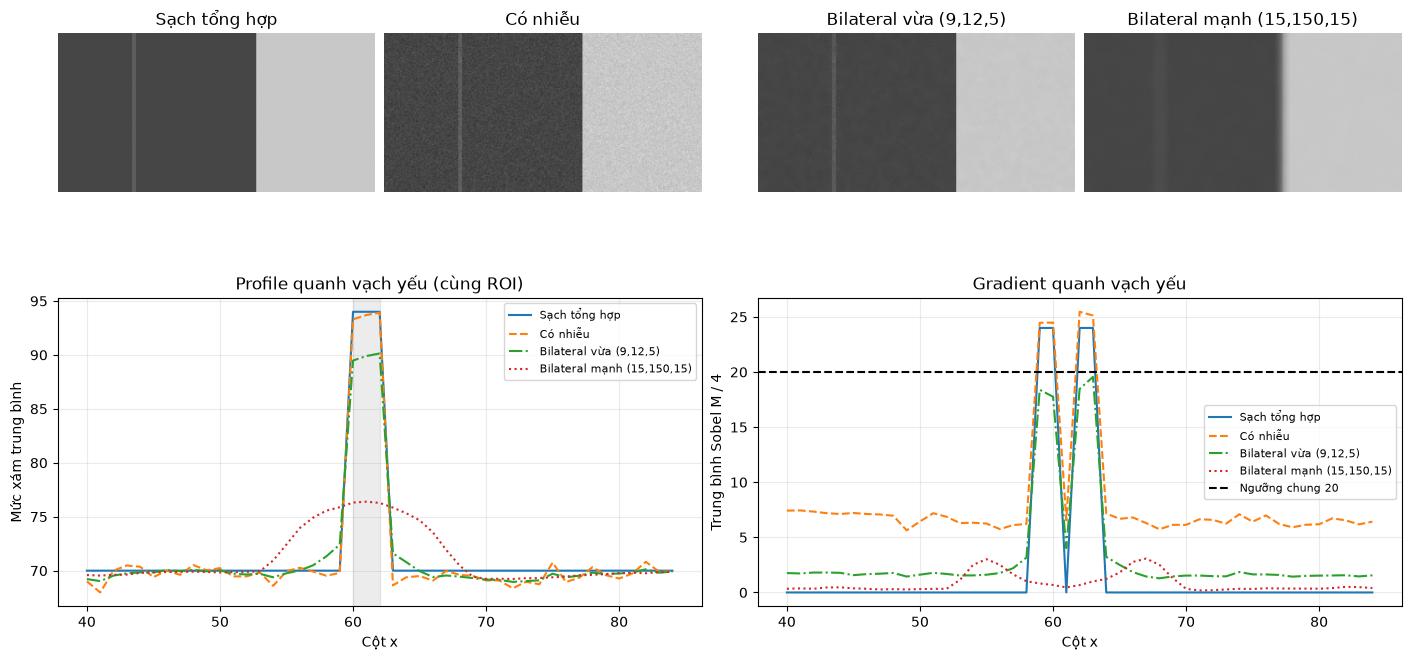

{'filter': 'Sạch tổng hợp', 'weak_stripe_contrast': 24.0, 'strong_step_contrast': 130.0, 'mse_to_clean': 0.0}
{'filter': 'Có nhiễu', 'weak_stripe_contrast': 24.2057, 'strong_step_contrast': 129.6813, 'mse_to_clean': 36.3784}
{'filter': 'Bilateral vừa (9,12,5)', 'weak_stripe_contrast': 20.3498, 'strong_step_contrast': 129.7396, 'mse_to_clean': 3.2161}
{'filter': 'Bilateral mạnh (15,150,15)', 'weak_stripe_contrast': 6.1233, 'strong_step_contrast': 129.8396, 'mse_to_clean': 41.2404}
Tương phản vạch: vừa 20.35, mạnh 6.12.
Đã lưu 4 PNG và 1 CSV.


In [6]:
synthetic = np.full((128, 256), 70, dtype=np.uint8)
synthetic[:, 160:] = 200
synthetic[:, 60:63] = 94
rng = np.random.default_rng(SEED)
synthetic_noisy = np.clip(synthetic.astype(np.float32) + rng.normal(0, 6, synthetic.shape), 0, 255).astype(np.uint8)
synth_variants = {
    'Sạch tổng hợp': synthetic,
    'Có nhiễu': synthetic_noisy,
    'Bilateral vừa (9,12,5)': apply_bilateral_filter(synthetic_noisy, 9, 12, 5),
    'Bilateral mạnh (15,150,15)': apply_bilateral_filter(synthetic_noisy, 15, 150, 15),
}
fig = plt.figure(figsize=(14, 7), constrained_layout=True)
grid = fig.add_gridspec(2, 4)
profile_ax = fig.add_subplot(grid[1, :2])
gradient_ax = fig.add_subplot(grid[1, 2:])
rows = []
for j, (name, image) in enumerate(synth_variants.items()):
    gray(fig.add_subplot(grid[0, j]), image, name)
    profile = image[16:112].mean(axis=0)
    weak_contrast = profile[60:63].mean() - (profile[50:56].mean() + profile[67:73].mean()) / 2
    step_contrast = profile[170:180].mean() - profile[140:150].mean()
    mse = np.mean((image.astype(np.float32) - synthetic.astype(np.float32)) ** 2)
    rows.append({'filter': name, 'weak_stripe_contrast': round(float(weak_contrast), 4),
                 'strong_step_contrast': round(float(step_contrast), 4), 'mse_to_clean': round(float(mse), 4)})
    style = ['-', '--', '-.', ':'][j]
    profile_ax.plot(np.arange(40, 85), profile[40:85], linestyle=style, label=name)
    grad_profile = (sobel_edges(image)[2] / 4)[16:112].mean(axis=0)
    gradient_ax.plot(np.arange(40, 85), grad_profile[40:85], linestyle=style, label=name)
profile_ax.set(title='Profile quanh vạch yếu (cùng ROI)', xlabel='Cột x', ylabel='Mức xám trung bình')
profile_ax.axvspan(60, 62, color='gray', alpha=0.15)
gradient_ax.set(title='Gradient quanh vạch yếu', xlabel='Cột x', ylabel='Trung bình Sobel M / 4')
gradient_ax.axhline(EDGE_THRESHOLD, color='black', linestyle='--', label='Ngưỡng chung 20')
for ax in (profile_ax, gradient_ax):
    ax.grid(alpha=0.25); ax.legend(fontsize=8)
finish(fig, '04_weak_edge_loss.png')
with (OUT / 'synthetic_metrics.csv').open('w', newline='', encoding='utf-8') as f:
    writer = csv.DictWriter(f, fieldnames=rows[0].keys())
    writer.writeheader(); writer.writerows(rows)
for row in rows:
    print(row)
print(f'Tương phản vạch: vừa {rows[2]["weak_stripe_contrast"]:.2f}, mạnh {rows[3]["weak_stripe_contrast"]:.2f}.')
assert rows[3]['weak_stripe_contrast'] < rows[2]['weak_stripe_contrast']
assert len(list(OUT.glob('*.png'))) == 4
print('Đã lưu 4 PNG và 1 CSV.')

**Kết quả:** tương phản vạch từ **24.00** ở ảnh sạch còn **20.35** sau lọc vừa và **6.12** sau lọc mạnh. Tương phản cạnh lớn đo xa vùng chuyển tiếp vẫn khoảng **129.74–129.84**, gần mức sạch 130; điều này không có nghĩa độ sắc tại chính vùng chuyển tiếp được giữ nguyên. Profile cho thấy đỉnh gradient vạch yếu giảm rõ rệt khi lọc mạnh. Ngay cả profile gradient trung bình sau lọc vừa cũng hơi dưới ngưỡng 20: ngưỡng cố định có thể bỏ sót cạnh yếu dù hình còn nhìn thấy. Profile trung bình không phải quyết định ngưỡng của từng pixel.

**Giải thích:** Với `sigma_color=150`, chênh lệch 24 của vạch có trọng số cường độ còn lớn nên các điểm nền và vạch bị trộn. Vùng lân cận 15 pixel rộng hơn vạch 3 pixel, khiến đáp ứng gradient vạch giảm và dễ rơi dưới ngưỡng cố định. Cạnh lớn có độ tương phản khác nên không thể suy từ việc giữ được cạnh lớn rằng mọi cạnh nhỏ đều được giữ.

Sobel/Prewitt đo thay đổi cường độ, vì vậy cũng nhạy với nhiễu. Bilateral là thỏa hiệp giữa giảm nhiễu và giữ chi tiết; cần chọn tham số theo mức nhiễu, độ tương phản và kích thước chi tiết. Thí nghiệm tổng hợp minh họa một cơ chế cụ thể, không thay thế đánh giá trên dữ liệu thật có nhãn cạnh.